In [1]:
import os
import numpy as np
import uproot
import sys

import matplotlib.pyplot as plt

## ROOT stuff
import ROOT
from ROOT import TFile, TTree, TCanvas
from ROOT import TH1F, TH2F
import ctypes
import copy

import iminuit

from v2Helpers import *

ROOT.gStyle.SetCanvasDefW(600)
ROOT.gStyle.SetCanvasDefH(500)

# ROOT.gErrorIgnoreLevel = ROOT.kFatal
ROOT.gROOT.SetBatch(False)
# ROOT.enableJSVis()
# ROOT.disableJSVis()

Welcome to JupyROOT 6.27/01


In [2]:
g4BasePath = os.environ.get("CF4G4")
print(g4BasePath)

/Users/austindestcroix/Desktop/school_holders/projects/sbc/g4cf4_newOptics/


### Compare with MC
I need to do two runs, one with LP and one bare. apply same 'rate scaling' to both datasets.

In [3]:
sys.path.append(os.environ.get("CF4HOME")+"/code1Analysis/")
sys.path.append(os.environ.get("CF4HOME")+"/comp1/helpers/")
import Comparator as comp
import MCdataSet as mcd
print(sys.path)

## Atown's stuff
from helpers.anaStructs import * # includes SORTING class/namespace
from helpers.getSPE import *
import helpers.graphBuilders as GB

# ------------- User Inputs ------------- #
NCHAN = 3
VERBOSE = False
ASK_MATPLOT = True
DO_2D = False
QVAR_USE = "qFlat"
PECUTVALUE = 0.5

defPath = str(os.environ["CF4HOME"]) + "/procData/"
rootPath = defPath + "/analysis1/"

runID_lp = [202206231023]
runID_bare = [202205201136]
physicsList = runID_bare + runID_lp
allRuns = physicsList

['/Users/austindestcroix/Desktop/school_holders/projects/sbc/CF4/comp2', '/Users/austindestcroix/packages/root_py311_v6_26.10/myInstall_p311/lib', '/Library/Frameworks/Python.framework/Versions/3.11/lib/python311.zip', '/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11', '/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/lib-dynload', '', '/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages', '/Users/austindestcroix/Desktop/school_holders/projects/sbc/CF4/code1Analysis/', '/Users/austindestcroix/Desktop/school_holders/projects/sbc/CF4/comp1/helpers/', '/Users/austindestcroix/Desktop/school_holders/projects/sbc/CF4/code1Analysis/', '/Users/austindestcroix/Desktop/school_holders/projects/sbc/CF4', '/Users/austindestcroix/Desktop/school_holders/projects/sbc/g4cf4_newOptics/', '/Users/austindestcroix/Desktop/school_holders/projects/sbc/g4cf4_newOptics/Batch/helpers']


In [4]:
# ------------- Main Analysis ------------- #
rcList = []
fList = []

for run in allRuns:
    file_path = rootPath + f"npv1_{run}.root"
    f = ROOT.TFile(file_path, "READ")
    fList.append(f)
    tt = f.Get("tt")
    
    rcObj = RunClass(run, tt, fname = file_path)
    rcList.append(rcObj)
    
    rcObj.computeSPE(width=15, verbose=VERBOSE, varname=QVAR_USE, channels=[i for i in range(NCHAN)], nbins = 150)
    rcObj.UprootConstructor()
    # rcList.append(rcObj)

if VERBOSE:
    input("say something to move past bkg SPE plots")

for rc in rcList:
    rc.print()

rcBare = SORTING.pickSingleRC(runID_bare[0], rcList)
rcLp = SORTING.pickSingleRC(runID_lp[0], rcList)



runID: 202205201136
Nevents: 217499.00,   time: 0.65 min
average Rate: 5558.14 Hz
chID:0: spe = 146.44 +/- 0.18     maxChi2 = 145.18
chID:1: spe = 153.75 +/- 0.09     maxChi2 = 199.77
chID:2: spe = 154.97 +/- 0.09     maxChi2 = 430.11

runID: 202206231023
Nevents: 515499.00,   time: 1.19 min
average Rate: 7243.99 Hz
chID:0: spe = 149.89 +/- 0.04     maxChi2 = 962.55
chID:1: spe = 152.41 +/- 0.04     maxChi2 = 656.02
chID:2: spe = 153.36 +/- 0.04     maxChi2 = 1195.08


Warning in <TSpectrum::SearchHighRes>: Peak buffer full
2025-12-11 15:44:38.608 Python[41547:87541700] WARNING: Secure coding is not enabled for restorable state! Enable secure coding by implementing NSApplicationDelegate.applicationSupportsSecureRestorableState: and returning YES.
Info in <TCanvas::MakeDefCanvas>:  created default TCanvas with name c1
Warning in <TSpectrum::SearchHighRes>: Peak buffer full
Warning in <TSpectrum::SearchHighRes>: Peak buffer full
Warning in <TSpectrum::SearchHighRes>: Peak buffer full
Warning in <TSpectrum::SearchHighRes>: Peak buffer full
Warning in <TSpectrum::SearchHighRes>: Peak buffer full


2
['chInfo', 'evTime', 'blineV', 'blineE', 'minV', 'timeMin', 'qFixed', 'qFlat', 'tFlatStart', 'tFlatEnd', 'qRCFixed', 'qRCFlat']
<TBranch 'qFixed' at 0x000169bcf390>


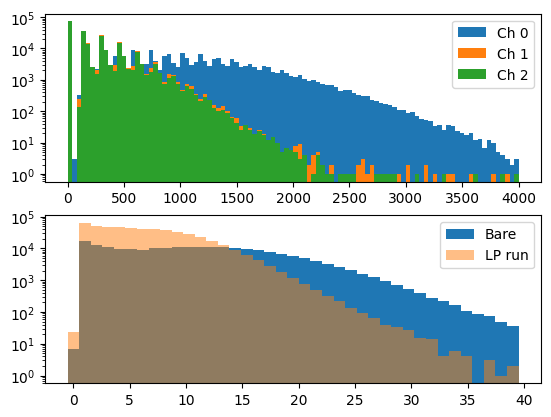

In [5]:
print(len(rcList))

print(rcBare.mttUp.keys())
print(rcBare.mttUp["qFixed"])

qraw = rcBare.mttUp[QVAR_USE].array(library="np")

# for rc in rcList:
#   qa = rc.GetSPEValues(qvar=QVAR_USE)

########################
fig, (axQ, axS) = plt.subplots(2, 1)

qraw = rcBare.mttUp[QVAR_USE].array(library="np")

binEdge = np.linspace(0, 4000, 101)
axQ.hist(qraw[:, 0], bins=binEdge, label="Ch 0")
axQ.hist(qraw[:, 1], bins=binEdge, label="Ch 1")
axQ.hist(qraw[:, 2], bins=binEdge, label="Ch 2")
axQ.legend()
axQ.set_yscale("log")

bE = np.linspace(-0.5, 39.5, 40)

z = axS.hist(rcBare.GetSPEArray(), bins=bE, label = "Bare")
z = axS.hist(rcLp.GetSPEArray(), bins=bE, alpha = 0.5, histtype="stepfilled", label = "LP run")

axS.set_yscale("log")

# axS.set_yscale("log")
axS.legend()
plt.show()
# axS.set_yscale("log")

---
### Workflow
? 'rate scaling' - R ?
look at absolute rates and if not very different, ignore. just fit spectrum

Light yield - Y

UV fraction - f

okay, looks like rates dont make sense. lets assume its from digitizer busy haha. just do vertical scaling

In [6]:
## usually use config.json file to organize all this
class storeConfig:
  pass
conf = storeConfig()
conf.NCA = 0.17
conf.binLow = -0.5
conf.binHigh = 39.5
conf.binWidth = 1.0
conf.Nbins = int((conf.binHigh - conf.binLow) / conf.binWidth)
print(f"Nbins: {conf.Nbins}")

## fitting ranges
conf.rangeLow = 6
conf.rangeHigh = 35
conf.compNbins = int((conf.rangeHigh - conf.rangeLow) / conf.binWidth)
print(f"comp Nbins: {conf.compNbins}")

Nbins: 40
comp Nbins: 29


/Users/austindestcroix/Desktop/school_holders/projects/sbc/g4cf4_newOptics/
loaded in: /Users/austindestcroix/Desktop/school_holders/projects/sbc/g4cf4_newOptics/batchOutput/alpha_sept25/4/Alpha_vf_0d9_bare.root
0.22381960562106518


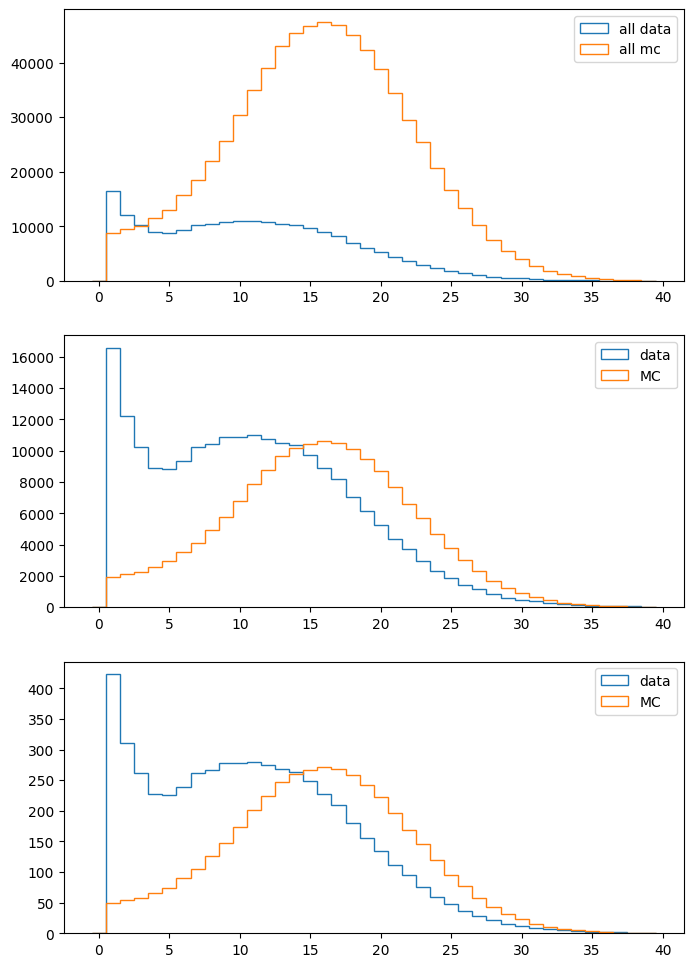

In [7]:
## load in MC data, compare to data
g4BasePath = os.environ.get("CF4G4")
print(g4BasePath)
sys.path.append(g4BasePath + "/Batch/helpers")
import G4_runClasses as g4rc
import Comparator as g4comp
g4Path = g4BasePath + "batchOutput/alpha_sept25"

## controlling the bins ##
binsDict = {"nbins": conf.Nbins, "low": 5, "high": conf.binHigh}
compBinsDict = {"firstBin": conf.rangeLow, "lastBin": conf.rangeHigh, "nbins": conf.compNbins, "mode":"x"}

## load MC data
mcBare_test = g4rc.FullMCRun(macName = g4Path+"/4/Alpha_vf_0d9_bare")
# mcBare_test.doCAcorrection_GeometricMC(nCA = conf.NCA)

## these should have same bin sizes
mcBare_test.setup_forComparison(Nbins = conf.Nbins, lowRange=conf.binLow, maxRange = conf.binHigh, variable = "mNPE")
rcBare.setup_forComparison_np(Nbins = conf.Nbins, lowRange=conf.binLow, maxRange = conf.binHigh, qvar=QVAR_USE, peCut=PECUTVALUE)

## plotting
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(8, 12))

ax1.hist(rcBare.mBinX, bins = rcBare.mBin_edges, weights = rcBare.mBin_rawCounts, histtype="step", label = "all data")
ax1.hist(mcBare_test.mBinX, bins = mcBare_test.mBin_Edges, weights = mcBare_test.mRaw_Counts, histtype="step", label = "all mc")
ax1.legend()

## build rc mc pair
testPair = g4comp.rcMCpair(rcBare, mcBare_test)
testPair.SetBinRanges(firstBin = conf.rangeLow, lastBin = conf.rangeHigh, mode="x")

# ## guess the rate scaling
scaleMC = testPair.GuessScaling() * testPair.GetPrefac()
print(scaleMC)

# scaleMC = fixRcMc.GetPrefac() * fixRcMcPair.GuessScaling()
# ## plotting ##
ax2.hist(rcBare.mBinX, bins = rcBare.mBin_edges, weights = rcBare.mBin_rawCounts, histtype="step", label = "data");
ax2.hist(mcBare_test.mBinX, bins = mcBare_test.mBin_Edges, weights = scaleMC * mcBare_test.mRaw_Counts, histtype="step", label = "MC");

ax2.legend()

ax3.hist(rcBare.mBinX, bins = rcBare.mBin_edges, weights = rcBare.mBin_rate, histtype="step", label = "data");
ax3.hist(mcBare_test.mBinX, bins = mcBare_test.mBin_Edges, weights = mcBare_test.mRaw_Counts * scaleMC / rcBare.GetRunTime(), histtype="step", label = "MC");
ax3.legend()

---
## need to make some new tools/plan here

1. hold both the LP and Bare data, and corresponding MC runs
2. wont do any rate scaling. and scaling LY is challenging because integer to float thing
3. simple solution. Fit both bare and LP MC spectra (high ends) with a gaussian. see how much to scale horizontally to fit the data's tail. 
4. scaling x LY gives actual LY
5. best fit mc dataset gives UV and Vis fraction 

In [8]:
## Gaussian fitting with iminuit
from iminuit import Minuit
from iminuit.cost import LeastSquares
import scipy.stats as stats

# Example: Fit the MC histogram
print("Fitting MC histogram with Gaussian...")

# Get the MC histogram data
mc_bin_centers = mcBare_test.mBinX
mc_counts = mcBare_test.mRaw_Counts * scaleMC  # use the scaled counts

# Only fit in the range where we have reasonable statistics
fit_mask = (mc_bin_centers >= conf.rangeLow) & (mc_bin_centers <= conf.rangeHigh) & (mc_counts > 0)
mc_centers_fit = mc_bin_centers[fit_mask]
mc_counts_fit = mc_counts[fit_mask]

# Perform the fit
mc_fit_result = fit_histogram_gaussian(mc_centers_fit, mc_counts_fit)

print(f"MC Fit Results:")
print(f"Amplitude: {mc_fit_result.values['amplitude']:.2f} ± {mc_fit_result.errors['amplitude']:.2f}")
print(f"Mean: {mc_fit_result.values['mean']:.2f} ± {mc_fit_result.errors['mean']:.2f}")
print(f"Sigma: {mc_fit_result.values['sigma']:.2f} ± {mc_fit_result.errors['sigma']:.2f}")
print(f"Chi2/ndf: {mc_fit_result.fval:.2f}/{len(mc_centers_fit) - 3}")

# Check if fit is valid
if mc_fit_result.valid:
    print("✓ Fit converged successfully")
else:
    print("✗ Fit did not converge properly")

Fitting MC histogram with Gaussian...
MC Fit Results:
Amplitude: 10613.69 ± 33.67
Mean: 15.39 ± 0.02
Sigma: 6.35 ± 0.02
Chi2/ndf: 18.98/26
✓ Fit converged successfully


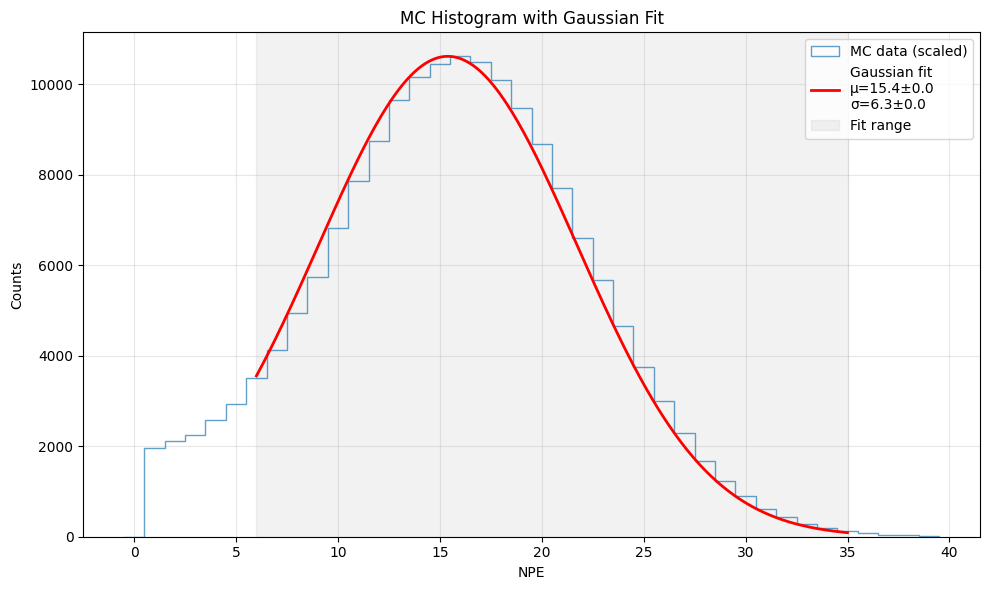


Covariance matrix:
┌─────────────────────────────────────────────────────────────────────────┐
│                                Migrad                                   │
├──────────────────────────────────┬──────────────────────────────────────┤
│ FCN = 18.98 (χ²/ndof = 0.7)      │              Nfcn = 69               │
│ EDM = 8.74e-06 (Goal: 0.0002)    │                                      │
├──────────────────────────────────┼──────────────────────────────────────┤
│          Valid Minimum           │   Below EDM threshold (goal x 10)    │
├──────────────────────────────────┼──────────────────────────────────────┤
│      No parameters at limit      │           Below call limit           │
├──────────────────────────────────┼──────────────────────────────────────┤
│             Hesse ok             │         Covariance accurate          │
└──────────────────────────────────┴──────────────────────────────────────┘
┌───┬───────────┬───────────┬───────────┬────────────┬────────────┬─

In [9]:
# Plot the fit result
fig, ax = plt.subplots(figsize=(10, 6))

# Plot the original histogram
ax.hist(mc_bin_centers, bins=mcBare_test.mBin_Edges, weights=mc_counts, 
        histtype="step", label="MC data (scaled)", alpha=0.7)

# Generate smooth curve for the fit
x_smooth = np.linspace(conf.rangeLow, conf.rangeHigh, 200)
y_fit = gaussian(x_smooth, 
                mc_fit_result.values['amplitude'], 
                mc_fit_result.values['mean'], 
                mc_fit_result.values['sigma'])

# Plot the fit
ax.plot(x_smooth, y_fit, 'r-', linewidth=2, 
        label=f'Gaussian fit\nμ={mc_fit_result.values["mean"]:.1f}±{mc_fit_result.errors["mean"]:.1f}\nσ={mc_fit_result.values["sigma"]:.1f}±{mc_fit_result.errors["sigma"]:.1f}')

# Plot just the fitted region for clarity
ax.axvspan(conf.rangeLow, conf.rangeHigh, alpha=0.1, color='gray', label='Fit range')

ax.set_xlabel('NPE')
ax.set_ylabel('Counts')
ax.set_title('MC Histogram with Gaussian Fit')
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Print covariance matrix (uncertainties)
print("\nCovariance matrix:")
print(mc_fit_result)

---
## MC fitting
Okay. lets do this. I need to loop through the folders in g4path, and open both the .root files (LP and bare).

1. open them as g4rc.FullMCRun(macName = g4Path+"/Alpha_vf_0d9_bare"), but you will need to find the filename programmatically
2. setup for comparison, usign the same bin config as above
3. make a wrapper function, so i can pass my mc object to fit the gaussian simply/easily
4. fit both root files. output the resulting fit params

okay now it gets a bit more complicated. i need to scale the x axis of the mc fits to compare to the data.
1. make a function that computes the chi2 between a given hisogram (data) and given mc fits. Each fit can be scaled vertically, but they have to share a common horizontal scaling. so 3 free parameters. Sbare, SLP, and LYscale. Minimize the output of this function.
2. apply this function in the loop over folders (happens for each folder)

In [10]:
import glob
import os

def chi2_data_mc_comparison(params, data_bare_hist, data_lp_hist, mc_bare_fit, mc_lp_fit, bin_centers):
  """
  Compute chi2 between data histograms and scaled MC Gaussian fits
  
  Parameters:
  params: [Sbare, SLP, LYscale] - vertical scales for bare/LP, horizontal scale for LY
  data_bare_hist: bare data histogram counts
  data_lp_hist: LP data histogram counts  
  mc_bare_fit: fitted Gaussian parameters for bare MC
  mc_lp_fit: fitted Gaussian parameters for LP MC
  bin_centers: x-axis bin centers
  
  Returns:
  chi2: combined chi2 value
  """
  Sbare, SLP, LYscale = params
  
  # Scale the MC fits horizontally (LY scaling) and vertically 
  mc_bare_scaled = Sbare * gaussian(bin_centers * LYscale, 
                                   mc_bare_fit.values['amplitude'],
                                   mc_bare_fit.values['mean'], 
                                   mc_bare_fit.values['sigma'])
  
  mc_lp_scaled = SLP * gaussian(bin_centers * LYscale,
                               mc_lp_fit.values['amplitude'],
                               mc_lp_fit.values['mean'],
                               mc_lp_fit.values['sigma'])
  
  # Calculate chi2 for both datasets (assuming Poisson errors)
  # Only use bins in the fit range
  fit_mask = (bin_centers >= conf.rangeLow) & (bin_centers <= conf.rangeHigh)
  
  data_bare_fit = data_bare_hist[fit_mask]
  data_lp_fit = data_lp_hist[fit_mask] 
  mc_bare_fit_vals = mc_bare_scaled[fit_mask]
  mc_lp_fit_vals = mc_lp_scaled[fit_mask]
  
  # Poisson errors (avoid zero errors)
  err_bare = np.sqrt(data_bare_fit)
  err_bare[err_bare == 0] = 1
  err_lp = np.sqrt(data_lp_fit)
  err_lp[err_lp == 0] = 1
  
  chi2_bare = np.sum((data_bare_fit - mc_bare_fit_vals)**2 / err_bare**2)
  chi2_lp = np.sum((data_lp_fit - mc_lp_fit_vals)**2 / err_lp**2)
  
  return chi2_bare + chi2_lp

def chi2_objective(Sbare, SLP, LYscale, data_bare_hist, data_lp_hist, mc_bare_fit, mc_lp_fit, bin_centers):
  """
  Objective function for iminuit - separate parameters for easier interface
  """
  return chi2_data_mc_comparison([Sbare, SLP, LYscale], data_bare_hist, data_lp_hist, mc_bare_fit, mc_lp_fit, bin_centers)

def fit_ly_scaling_iminuit(data_bare_hist, data_lp_hist, mc_bare_fit, mc_lp_fit, bin_centers):
  """
  Find best LY scaling and vertical scales to match data using iminuit
  """
  
  # Create a partial function with fixed arguments
  def chi2_func(Sbare, SLP, LYscale):
    return chi2_objective(Sbare, SLP, LYscale, data_bare_hist, data_lp_hist, mc_bare_fit, mc_lp_fit, bin_centers)
  
  # Create Minuit object with initial guesses
  m = Minuit(chi2_func, Sbare=1.0, SLP=1.0, LYscale=1.0)
  
  # Set parameter limits (all positive)
  m.limits['Sbare'] = (0.1, 10)
  m.limits['SLP'] = (0.1, 10) 
  m.limits['LYscale'] = (0.1, 3)
  
  # Perform minimization
  m.migrad()
  
  return m

Starting LY scaling optimization for each MC folder...

--- Processing folder: /Users/austindestcroix/Desktop/school_holders/projects/sbc/g4cf4_newOptics/batchOutput/alpha_sept25/8 ---
loaded in: /Users/austindestcroix/Desktop/school_holders/projects/sbc/g4cf4_newOptics/batchOutput/alpha_sept25/8/Alpha_vf_0d4_LP.root
loaded in: /Users/austindestcroix/Desktop/school_holders/projects/sbc/g4cf4_newOptics/batchOutput/alpha_sept25/8/Alpha_vf_0d4_bare.root
Optimization successful:
  Sbare = 0.908 ± 0.003
  SLP = 0.984 ± 0.002
  LY scale = 0.958 ± 0.001
  Min chi2 = 15501.90

--- Processing folder: /Users/austindestcroix/Desktop/school_holders/projects/sbc/g4cf4_newOptics/batchOutput/alpha_sept25/7 ---
loaded in: /Users/austindestcroix/Desktop/school_holders/projects/sbc/g4cf4_newOptics/batchOutput/alpha_sept25/7/Alpha_vf_0d3_LP.root
loaded in: /Users/austindestcroix/Desktop/school_holders/projects/sbc/g4cf4_newOptics/batchOutput/alpha_sept25/7/Alpha_vf_0d3_bare.root
Optimization successful:


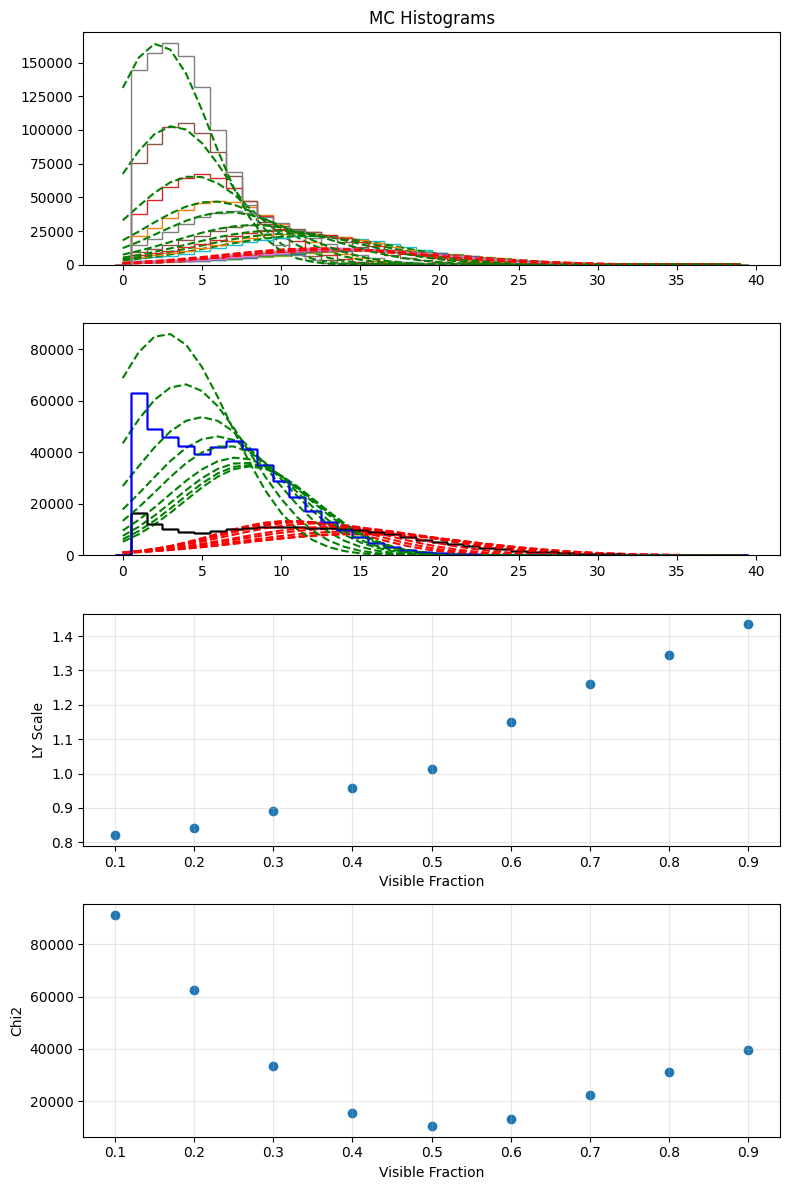

: 

In [ ]:
# Updated loop with LY scaling optimization using iminuit
from iminuit import Minuit

overallResults = []
# Get data histograms (use the same ones from earlier)
data_bare_hist = rcBare.mBin_rawCounts

rcLp.setup_forComparison_np(Nbins = conf.Nbins, lowRange=conf.binLow, maxRange = conf.binHigh, qvar=QVAR_USE, peCut=PECUTVALUE) 
data_lp_hist = rcLp.mBin_rawCounts
data_bin_centers = rcBare.mBinX

print("Starting LY scaling optimization for each MC folder...")

fig, (ax1, ax2, ax3, ax4) = plt.subplots(4, 1, figsize=(8, 12))

folders = sorted(os.listdir(g4Path))

for folder in folders[::-1]:  # Test with first 2 folders
  folder_path = os.path.join(g4Path, folder)
  print(f"\n--- Processing folder: {folder_path} ---")
  
  # continue
  # Find LP and bare files in this folder
  lp_files = glob.glob(os.path.join(folder_path, "*LP*"))
  bare_files = glob.glob(os.path.join(folder_path, "*bare*"))
  
  if not lp_files or not bare_files:
    print(f"Skipping {folder}: missing LP or bare files")
    continue
  
  # Take first file of each type (remove .root extension for g4rc)
  lp_file = os.path.splitext(lp_files[0])[0]
  bare_file = os.path.splitext(bare_files[0])[0]
  
  try:
    # Load MC data
    mc_lp = g4rc.FullMCRun(macName=lp_file)
    mc_bare = g4rc.FullMCRun(macName=bare_file)
    
    # Setup for comparison using same config
    mc_lp.setup_forComparison(Nbins=conf.Nbins, lowRange=conf.binLow, maxRange=conf.binHigh, variable="mNPE")
    mc_bare.setup_forComparison(Nbins=conf.Nbins, lowRange=conf.binLow, maxRange=conf.binHigh, variable="mNPE")
    
    ## apply scaling
    pairBare = g4comp.rcMCpair(rcBare, mc_bare)
    pairBare.SetBinRanges(firstBin=conf.rangeLow, lastBin=conf.rangeHigh, mode="x")
    pairLp = g4comp.rcMCpair(rcLp, mc_lp)
    pairLp.SetBinRanges(firstBin=conf.rangeLow, lastBin=conf.rangeHigh, mode="x")
    
    mc_bare.m_scaledCounts = mc_bare.mRaw_Counts * pairBare.GuessScaling() * pairBare.GetPrefac()
    mc_lp.m_scaledCounts = mc_lp.mRaw_Counts * pairLp.GuessScaling() * pairLp.GetPrefac()

    # Fit both histograms with Gaussians
    fit_bare = fit_mc_histogram(mc_bare)
    fit_lp = fit_mc_histogram(mc_lp)
    
    if not (fit_lp.valid and fit_bare.valid):
      print(f"Skipping {folder}: invalid fits")
      continue
    
    # print(fit_bare)
    # print(fit_lp)
    
    ax1.hist(mc_bare.mBinX, mc_bare.mBin_Edges, weights=mc_bare.m_scaledCounts, histtype="step", label=f"{folder} Bare MC")
    ax1.hist(mc_lp.mBinX, mc_lp.mBin_Edges, weights=mc_lp.m_scaledCounts, histtype="step", label=f"{folder} LP MC")
    
    ax1.plot(data_bin_centers, fit_bare.values['amplitude'] * np.exp(-0.5 * ((data_bin_centers - fit_bare.values['mean']) / fit_bare.values['sigma'])**2), 'r--', label=f"{folder} Bare Fit")
    ax1.plot(data_bin_centers, fit_lp.values['amplitude'] * np.exp(-0.5 * ((data_bin_centers - fit_lp.values['mean']) / fit_lp.values['sigma'])**2), 'g--', label=f"{folder} LP Fit")
    
    # Find optimal LY scaling using iminuit
    opt_result = fit_ly_scaling_iminuit(data_bare_hist, data_lp_hist, fit_bare, fit_lp, data_bin_centers)
    if opt_result.valid:
      Sbare_opt = opt_result.values['Sbare']
      SLP_opt = opt_result.values['SLP'] 
      LYscale_opt = opt_result.values['LYscale']
      chi2_min = opt_result.fval
      
      print(f"Optimization successful:")
      print(f"  Sbare = {Sbare_opt:.3f} ± {opt_result.errors['Sbare']:.3f}")
      print(f"  SLP = {SLP_opt:.3f} ± {opt_result.errors['SLP']:.3f}")  
      print(f"  LY scale = {LYscale_opt:.3f} ± {opt_result.errors['LYscale']:.3f}")
      print(f"  Min chi2 = {chi2_min:.2f}")
      
      # Store extended results
      result = {
        'folder': folder,
        'lp_mean': fit_lp.values['mean'],
        'bare_mean': fit_bare.values['mean'],
        'Sbare': Sbare_opt,
        'Sbare_err': opt_result.errors['Sbare'],
        'SLP': SLP_opt,
        'SLP_err': opt_result.errors['SLP'],
        'visFrac': mc_lp.mPhysPars.vf,
        'LYscale': LYscale_opt,
        'LYscale_err': opt_result.errors['LYscale'],
        'chi2': chi2_min,
        'opt_success': True
      }

      ax2.plot(data_bin_centers, Sbare_opt * gaussian(data_bin_centers * LYscale_opt,
                                                       amplitude = fit_bare.values['amplitude'],
                                                       mean = fit_bare.values['mean'],
                                                       sigma = fit_bare.values['sigma']), 'r--', label=f"{folder} Bare Fit (opt)")
      ax2.plot(data_bin_centers, SLP_opt * gaussian(data_bin_centers * LYscale_opt,
                                                    amplitude = fit_lp.values['amplitude'],
                                                    mean = fit_lp.values['mean'],
                                                    sigma = fit_lp.values['sigma']), 'g--', label=f"{folder} LP Fit (opt)")

      ax2.hist(data_bin_centers, bins=rcBare.mBin_edges, weights=data_bare_hist, histtype="step", label="Data Bare", color='black', alpha=0.5)
      ax2.hist(data_bin_centers, bins=rcLp.mBin_edges, weights=data_lp_hist, histtype="step", label="Data LP", color='blue', alpha=0.5)

    else:
      print(f"Optimization failed to converge")
      result = {
        'folder': folder,
        'lp_mean': fit_lp.values['mean'],
        'bare_mean': fit_bare.values['mean'],
        'opt_success': False
      }
    
    overallResults.append(result)
    
  except Exception as e:
    print(f"Error processing {folder}: {e}")
    continue

# ax1.legend()
# ax1.set_yscale("log")
ax1.set_title("MC Histograms")

# ax2.legend()

## sort organize results by visible fraction
overallResults = sorted(overallResults, key=lambda x: x.get('visFrac', 0))

# Extract data for scatter plots - only successful fits
successful_results = [res for res in overallResults if res.get('opt_success', False)]
x_vf = [round(float(res['visFrac']), 2) for res in successful_results]
yly = [res['LYscale'] for res in successful_results]
ychi2 = [round(res['chi2'], 1) for res in successful_results]

# Scatter plots with proper axis handling
ax3.scatter(x_vf, yly)
ax3.set_xlabel("Visible Fraction")
ax3.set_ylabel("LY Scale")
ax3.grid(True, alpha=0.3)

# ax3.set_x

ax4.scatter(x_vf, ychi2)
ax4.set_xlabel("Visible Fraction")
ax4.set_ylabel("Chi2")
ax4.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# print(f"\n--- Summary of optimization results ---")
# for r in results:
#   if r.get('opt_success', False):
#     print(f"Folder {r['folder']}: LY={r['LYscale']:.3f}±{r['LYscale_err']:.3f}, chi2={r['chi2']:.1f}")
#   else:
#     print(f"Folder {r['folder']}: optimization failed")